<a href="https://colab.research.google.com/github/aldo02032004/naufaldo.github.io/blob/main/2_ML_Dev_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **(Second development)**
# Figurative Language Classification using Machine Learning

## Setting Up the Program

### Installing all the needed library

In [1]:
# torch, transformers, scikit-learn, pandas, numpy, nltk are preinstalled on Colab
%pip install -q ftfy PySastrawi datasets accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.2/211.2 kB 7.2 MB/s eta 0:00:00


### Importing the needed library

In [2]:
import io, re, gc, json, codecs, shutil
from google.colab import files, drive

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ftfy
import nltk
from nltk.corpus import stopwords as nltk_stopwords
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import LinearSVC
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay
from scipy.stats import bootstrap
from scipy.special import softmax

import torch
from datasets import Dataset
from transformers import (AutoConfig, AutoTokenizer, AutoModelForSequenceClassification, Trainer,
                          TrainingArguments, EarlyStoppingCallback, set_seed)

nltk.download('stopwords', quiet=True)
pd.set_option('display.max_colwidth', None)   # show full texts in tables

In [10]:
# mixed-encoding CSVs: decode as UTF-8, and read only the bytes that fail as Windows-1252 (e.g. 0x92 = ’)
codecs.register_error('cp1252_fallback',
                      lambda e: (e.object[e.start:e.end].decode('cp1252', errors='replace'), e.end))

def read_uploaded_file(name, content):
    # some files have a title row above the header, so start from the row that holds 'Mentions'
    if name.lower().endswith(('.xlsx', '.xls')):
        peek = pd.read_excel(io.BytesIO(content), header=None, nrows=10)
        header_row = peek.index[peek.eq('Mentions').any(axis=1)][0]
        return pd.read_excel(io.BytesIO(content), header=header_row)

    text = content.decode('utf-8-sig', errors='cp1252_fallback')
    lines = text.splitlines()[:10]
    header_row = next(i for i, line in enumerate(lines) if 'Mentions' in line)
    sep = ';' if lines[header_row].count(';') > lines[header_row].count(',') else ','   # daily export uses ';'
    return pd.read_csv(io.StringIO(text), skiprows=header_row, sep=sep)

uploaded = files.upload()   # pick both files (CSV or Excel): the labeled training file and the file to predict
dataframes = {name: read_uploaded_file(name, content) for name, content in uploaded.items()}
for name, df in dataframes.items():
    print(name, df.shape)

# the file with a 'Majas' column is the training data, the other one gets predicted
training_df = next((df for df in dataframes.values() if 'Majas' in df.columns), None)
predict_df = next((df for df in dataframes.values() if 'Majas' not in df.columns), None)
assert training_df is not None, "No training file (with a 'Majas' column) uploaded."
assert predict_df is not None, "No file to predict uploaded."
training_df.head(1)

Saving train_data.xlsx - Sheet1.csv to train_data.xlsx - Sheet1 (1).csv
Saving daily_16okt_Prabowo.xlsx to daily_16okt_Prabowo.xlsx
train_data.xlsx - Sheet1 (1).csv (13146, 7)
daily_16okt_Prabowo.xlsx (6209, 13)


,x,Media,Author,Mentions,Sentiment,Emotion,Majas
0,2026-08-14 07:10:34,Threads,NaN,Kata seekor prabodoh asubiantolol : yg penting ternak suara buat pemilu 2029. Sebelom jadi bangkai najis harus 2 periode dong.,Negative,Anger,Sindiran


In [11]:
def prepare_time(data, date_col='Date'):
    # parse date into datetime, sort oldest -> newest, and return the date range
    data = data.copy()
    if date_col != 'Date':
        data = data.rename(columns={date_col: 'Date'})
    data['Date'] = pd.to_datetime(data['Date'], format='mixed', dayfirst=True)
    data = data.sort_values('Date')
    start_date, end_date = (d.strftime('%d %b %Y') for d in data['Date'].iloc[[0, -1]])
    return data, start_date, end_date

# training_df contains 'x' instead of 'Date', and lacks 'Type'
training_df1, start_date, end_date = prepare_time(
    training_df[['x', 'Media', 'Mentions', 'Sentiment', 'Majas']],
    date_col='x'
)
print(start_date, '-', end_date)
training_df1

01 Jan 2026 - 31 Aug 2026


,Date,Media,Mentions,Sentiment,Majas
10020,2026-01-01 00:33:55,Tiktok,Prabowo sambut tahun baru obati duka bencana sumatera #prabowo #gerindra,Positive,Pujian
3787,2026-01-01 02:10:01,Tiktok,"Senyum pak Prabowo saat disambut warga Tapanuli Selatan 🥹💗 Untuk kesekian kalinya pak prabowo berkunjung ke Sumatera dan sekarang beliau datang ke Tapanuli Selatan. Sebelumnya, Wakil Ketua DPR Sufmi Dasco Ahmad dan UKP Raffi Ahmad sudah berkunjung ke Aceh. Ini merupakan bukti bahwa Pemrintah bersana DPR RI hadir membawa dukungan dan bantuan untuk warga korban bencana Sumatera-Aceh 🥺❤ #prabowosubianto #presidenprabowo #tahunbaru2026 #tapanuliselatan #fyp",Positive,Pujian
7148,2026-01-01 03:04:10,Youtube,"Malam Tahun Baru di Tapanuli Selatan, Presiden Prabowo Bersama Warga Terdampak Bencana. prabowo #tapsel #indonesia.",Neutral,NaN
11137,2026-01-01 03:05:45,Youtube,ðððâ¼ï¸#shorts#politics#polri#pejabat#prabowo#jokowi#lucu.,Neutral,NaN
4149,2026-01-01 03:20:26,Tiktok,"Selamat Tahun Baru Keluarga besar SPPG Tempeh & Yayasan Tempeh Community Independent mengucapkan selamat tahun baru. Terima kasih atas dukungan dan kebersamaan yang telah terjalin. Semoga di tahun yang baru ini kita selalu diberi kesehatan, semangat, dan kekuatan untuk terus berbagi serta memberi manfaat bagi sesama. Tahun baru, harapan baru. Mari melangkah bersama dengan optimisme. #MakanBergiziGratis #SPPGTempeh #MBG #TahunBaru2026 #Prabowo",Positive,Literal
...,...,...,...,...,...
12184,2026-08-31 23:32:59,Youtube,ahok sentil prabowo#new #shorts #viral,Negative,NaN
6422,2026-08-31 23:36:49,News,"Realitarakyat.com &mdash; Presiden RI Prabowo Subianto menegaskan bahwa komposisi koalisi pemerintahannya yang didukung oleh delapan partai politik saat ini sudah sangat efisien untuk mengelola negara sebesar Indonesia.\n\nPernyataan tersebut disampaikan Prabowo saat memberikan sambutan dalam penutupan Muktamar ke-35 Nahdlatul Ulama (NU) di Pondok Pesantren Tambakberas, Jombang, Jawa Timur, Senin (31/8/2026).\n\nPrabowo menjelaskan bahwa berkoalisi merupakan suatu keniscayaan dalam sistem demokrasi Indonesia.\n\nMenurut Presiden, wilayah Indonesia yang luasnya setara dengan gabungan 27 negara Uni Eropa serta jumlah penduduk yang hampir menyentuh 300 juta jiwa tidak mungkin hanya dikelola oleh satu partai tunggal.\n\n&ldquo;Kita ini sekarang delapan partai, sudah luar biasa efisiennya. Banyak negara lain mungkin belasan partai, puluhan partai. Tidak mungkin negara sebesar ini dipimpin hanya satu partai,&rdquo; ujar Prabowo.\n\nDalam kesempatan tersebut, Presiden menepis kritik publik yang menyebut kabinetnya sebagai kabinet gemuk dan tidak efisien.\n\nIa menekankan bahwa pemerintahan membutuhkan stabilitas politik dan ketenangan agar program kerja berjalan optimal.\n\nGuna memperkuat argumennya, Prabowo membandingkan kondisi stabilitas politik Indonesia dengan negara tetangga seperti Timor Leste yang memiliki 28 anggota kabinet meski populasi penduduknya hanya sekitar satu juta jiwa.\n\nPresiden juga menyinggung dinamika politik di negara maju seperti Jepang dan Inggris yang sering mengalami pergantian perdana menteri dalam kurun lima hingga enam tahun terakhir. (*)\n\n",Positive,NaN
11854,2026-08-31 23:38:08,Instagram,"gaad mau saling follow kh wahai anak"" jendral",Positive,NaN
12920,2026-08-31 23:43:32,Instagram,"Alhamdulillah MBG di Sumbar selalu amanah dan aman selama ini, bahkan MBG di Sumbar ada dendeng dan rendang, masyaallah tetap amanah ranah minangku😍",Positive,NaN


In [17]:
# typo fixes + grouping of figures of speech into 4 classes
label_map = {
    'sarkas': 'sindiran',
    'sarkasme': 'sindiran', 'ironi': 'sindiran', 'satire': 'sindiran', 'sinisme': 'sindiran',
    'hiperbola': 'perbandingan', 'simile': 'perbandingan', 'metafora': 'perbandingan',
    'repetisi': 'penegasan', 'retoris': 'penegasan', 'skeptis': 'penegasan',
    'kritik': 'penegasan', 'literal': 'penegasan', 'pujian': 'penegasan',
    'pertentangan': 'pertentangan', 'paradoks': 'pertentangan', 'antitesis': 'pertentangan',
    'neutral': 'irrelevant'
}
training_df1['label'] = training_df1['Majas'].str.strip().str.lower().replace(label_map)

# drop empty and irrelevant labels
training_df1 = training_df1[training_df1['label'].notna() &
                            (training_df1['label'] != 'irrelevant')].reset_index(drop=True)

# stop if an unknown label appears (changed from strict equality to subset check to handle 0-count classes)
EXPECTED = {'sindiran', 'perbandingan', 'penegasan', 'pertentangan'}
assert set(training_df1['label']).issubset(EXPECTED), set(training_df1['label']) - EXPECTED

training_df1['label'].value_counts()

,count
label,
penegasan,4431
sindiran,1316
perbandingan,171


## Cleaning Data

In [18]:
# figurative markers that must never be removed as stopwords
protected = {
    # comparison: protects 'perbandingan'
    'seperti', 'bagai', 'bagaikan', 'laksana', 'layaknya', 'bak',
    'ibarat', 'umpama', 'seumpama', 'serupa', 'mirip', 'semisal',
    # contrast: protects 'pertentangan'
    'tapi', 'tetapi', 'namun', 'meskipun', 'walaupun', 'walau',
    'kendati', 'kendatipun', 'padahal', 'sedangkan', 'sebaliknya', 'meski', 'biarpun',
    # emphasis / intensifiers: protects 'penegasan' and hyperbole
    'sangat', 'banget', 'benar-benar', 'sungguh', 'amat', 'sekali',
    'memang', 'justru', 'malah', 'bahkan', 'betul-betul', 'paling', 'sumpah',
    # insinuation / rhetorical particles: protects 'sindiran'
    'kan', 'kok', 'masa', 'masak', 'katanya', 'konon', 'ternyata',
    'memangnya', 'toh', 'lho', 'dong', 'sih',
    # negation: flips polarity, never strip regardless of category
    'tidak', 'bukan', 'tak', 'jangan', 'belum',
    # English code-switching: comparison, contrast, emphasis
    'like', 'literally', 'but', 'however', 'though',
    'actually', 'really', 'totally', 'absolutely', 'extra', 'very',
    # English sarcasm / insinuation: the ironic tone code-switching carries in ID social media
    'wow', 'great', 'nice', 'cool', 'sure', 'right', 'whatever', 'obviously',
}

# Indonesian (Sastrawi) + English stopwords, minus the protected words (used by NB and SVM)
base_stopwords = ({w.lower() for w in StopWordRemoverFactory().get_stop_words()} |
                  {w.lower() for w in nltk_stopwords.words('english')})
stopwords = sorted(base_stopwords - protected)

# keep hyphenated words ("benar-benar") as one token
TOKEN_PATTERN = r"(?u)\b\w[\w-]*\w\b"

In [19]:
slang_dict = {   # slang -> standard word, applied in clean()
    "gak": "tidak", "ga": "tidak", "nggak": "tidak", "tdk": "tidak",
    "bgt": "banget", "yg": "yang", "krn": "karena", "krna": "karena", "karna": "karena",
    "sm": "sama", "utk": "untuk", "dr": "dari", "skrg": "sekarang",
    "dgn": "dengan", "dg": "dengan", "org": "orang",
    "tp": "tapi", "spt": "seperti", "kayak": "seperti", "kaya": "seperti", "kyk": "seperti",
    "blm": "belum", "jgn": "jangan", "emg": "memang", "emang": "memang",
    "jd": "jadi", "jg": "juga", "aja": "saja", "aj": "saja",
    "udah": "sudah", "udh": "sudah", "dah": "sudah",
    "gmn": "bagaimana", "knp": "kenapa", "kalo": "kalau", "klo": "kalau",
    "trs": "terus", "trus": "terus", "gini": "begini", "gitu": "begitu",
    "sy": "saya", "km": "kamu", "gw": "saya", "gue": "saya", "lo": "kamu", "lu": "kamu",
    "hrs": "harus", "bs": "bisa", "msh": "masih", "dlm": "dalam",
    "sblm": "sebelum", "stlh": "setelah", "pd": "pada", "pgn": "ingin", "pengen": "ingin",
    "liat": "lihat", "abis": "habis",
    "bkn": "bukan", "gpp": "tidak apa-apa", "gapapa": "tidak apa-apa", "gaada": "tidak ada",
    "cmn": "cuma", "cuman": "cuma",
    "mksh": "terima kasih", "makasih": "terima kasih",
    "moga": "semoga", "smoga": "semoga",
    "wkt": "waktu", "cpt": "cepat", "lg": "lagi", "lgi": "lagi",
    "sll": "selalu", "sllu": "selalu", "prnh": "pernah",
    "sndiri": "sendiri", "stiap": "setiap", "byk": "banyak", "dikit": "sedikit",
    "dtg": "datang", "krg": "kurang", "ato": "atau",
    "pke": "pakai", "pake": "pakai", "kudu": "harus", "musti": "harus",
    "denger": "dengar", "kasih": "beri", "bikin": "buat",
    "brp": "berapa", "gmna": "bagaimana", "knpa": "kenapa",
    "walopun": "walaupun",
    # figurative-relevant: these change how a sentence reads as majas
    "kayanya": "sepertinya", "kykny": "sepertinya", "emgnya": "memangnya",
    # extend this from your own corpus's most frequent non-dictionary tokens
}

def clean(text):
    text = ftfy.fix_text(str(text)).lower()           # repair broken encoding
    text = re.sub(r"^rt\s+@\w+:?", " ", text)         # retweet prefix
    text = re.sub(r"http\S+|www\.\S+", " ", text)    # URL
    text = re.sub(r"@\w+", " ", text)                # mention
    text = text.replace("#", " ")                     # keep hashtag word
    return " ".join(slang_dict.get(w, w) for w in text.split())

training_df2 = training_df1.copy()
training_df2['text_clean'] = training_df2['Mentions'].apply(clean)
training_df2 = (
    training_df2[training_df2['text_clean'].str.len() > 0]
    .drop_duplicates(subset='text_clean')
    .reset_index(drop=True)
)
print(len(training_df1), '->', len(training_df2), 'rows after dropping empty / duplicate texts')
training_df2[['Mentions', 'text_clean']].head(5)

5918 -> 5896 rows after dropping empty / duplicate texts


,Mentions,text_clean
0,Prabowo sambut tahun baru obati duka bencana sumatera #prabowo #gerindra,prabowo sambut tahun baru obati duka bencana sumatera prabowo gerindra
1,"Senyum pak Prabowo saat disambut warga Tapanuli Selatan 🥹💗 Untuk kesekian kalinya pak prabowo berkunjung ke Sumatera dan sekarang beliau datang ke Tapanuli Selatan. Sebelumnya, Wakil Ketua DPR Sufmi Dasco Ahmad dan UKP Raffi Ahmad sudah berkunjung ke Aceh. Ini merupakan bukti bahwa Pemrintah bersana DPR RI hadir membawa dukungan dan bantuan untuk warga korban bencana Sumatera-Aceh 🥺❤ #prabowosubianto #presidenprabowo #tahunbaru2026 #tapanuliselatan #fyp","senyum pak prabowo saat disambut warga tapanuli selatan 🥹💗 untuk kesekian kalinya pak prabowo berkunjung ke sumatera dan sekarang beliau datang ke tapanuli selatan. sebelumnya, wakil ketua dpr sufmi dasco ahmad dan ukp raffi ahmad sudah berkunjung ke aceh. ini merupakan bukti bahwa pemrintah bersana dpr ri hadir membawa dukungan dan bantuan untuk warga korban bencana sumatera-aceh 🥺❤ prabowosubianto presidenprabowo tahunbaru2026 tapanuliselatan fyp"
2,"Selamat Tahun Baru Keluarga besar SPPG Tempeh & Yayasan Tempeh Community Independent mengucapkan selamat tahun baru. Terima kasih atas dukungan dan kebersamaan yang telah terjalin. Semoga di tahun yang baru ini kita selalu diberi kesehatan, semangat, dan kekuatan untuk terus berbagi serta memberi manfaat bagi sesama. Tahun baru, harapan baru. Mari melangkah bersama dengan optimisme. #MakanBergiziGratis #SPPGTempeh #MBG #TahunBaru2026 #Prabowo","selamat tahun baru keluarga besar sppg tempeh & yayasan tempeh community independent mengucapkan selamat tahun baru. terima beri atas dukungan dan kebersamaan yang telah terjalin. semoga di tahun yang baru ini kita selalu diberi kesehatan, semangat, dan kekuatan untuk terus berbagi serta memberi manfaat bagi sesama. tahun baru, harapan baru. mari melangkah bersama dengan optimisme. makanbergizigratis sppgtempeh mbg tahunbaru2026 prabowo"
3,"happy new year death to israel, prabowo, dan antek-anteknya 🙂‍↕️","happy new year death to israel, prabowo, dan antek-anteknya 🙂‍↕️"
4,habib bahar sedih desak prabowo bencana aceh segera jadikan bencana nasional.,habib bahar sedih desak prabowo bencana aceh segera jadikan bencana nasional.


In [20]:
# stratified split 70 / 15 / 15
train_df, temp_df = train_test_split(
    training_df2, test_size=0.30, stratify=training_df2['label'], random_state=42)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df['label'], random_state=42)

X_train, y_train = train_df['text_clean'], train_df['label']
X_val, y_val = val_df['text_clean'], val_df['label']
X_test, y_test = test_df['text_clean'], test_df['label']

for name, d in [('train', train_df), ('val', val_df), ('test', test_df)]:
    dist = d['label'].value_counts(normalize=True).round(2).to_dict()
    print(name, len(d), dist)

# leakage check: identical texts in train and val/test
overlap = set(X_train) & (set(X_val) | set(X_test))
print('identical texts:', len(overlap))

train 4127 {'penegasan': 0.75, 'sindiran': 0.22, 'perbandingan': 0.03}
val 884 {'penegasan': 0.75, 'sindiran': 0.22, 'perbandingan': 0.03}
test 885 {'penegasan': 0.75, 'sindiran': 0.22, 'perbandingan': 0.03}
identical texts: 0


# Majority Baseline

In [21]:
majority = DummyClassifier(strategy='most_frequent')
majority.fit(X_train, y_train)

maj_f1 = f1_score(y_val, majority.predict(X_val), average='macro')
print('Majority val macro F1:', round(maj_f1, 3))

Majority val macro F1: 0.285


# Naive Bayes

In [22]:
# shared by NB and SVM: TF-IDF + classifier in one Pipeline, so cross-validation never leaks
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def tune(name, clf, clf_grid):
    # grid search with CV on the train set only, then score on val
    pipe = Pipeline([
        ('tfidf', TfidfVectorizer(token_pattern=TOKEN_PATTERN, sublinear_tf=True)),
        ('clf', clf),
    ])
    grid = {
        'tfidf__ngram_range': [(1, 1), (1, 2)],
        'tfidf__stop_words': [None, stopwords],   # with AND without
        'tfidf__min_df': [1, 2],
        **clf_grid,
    }
    search = GridSearchCV(pipe, grid, cv=cv, scoring='f1_macro', n_jobs=-1)
    search.fit(X_train, y_train)
    val_f1 = f1_score(y_val, search.predict(X_val), average='macro')
    print(name, 'best params:', search.best_params_)
    print(name, 'CV macro F1:', round(search.best_score_, 3))
    print(name, 'val macro F1:', round(val_f1, 3))
    top_words(search.best_estimator_)
    return search

def top_words(pipe, n=10):
    # what the model learned: if these are topic names or noise instead of figurative markers, it learns the wrong thing
    vocab = np.array(pipe.named_steps['tfidf'].get_feature_names_out())
    clf = pipe.named_steps['clf']
    weights = clf.coef_ if hasattr(clf, 'coef_') else clf.feature_log_prob_   # SVM / Naive Bayes
    for cls, w in zip(clf.classes_, weights):
        print(cls, '->', ', '.join(vocab[np.argsort(w)[-n:][::-1]]))

In [23]:
# Complement NB handles imbalanced classes better than plain Multinomial NB
nb_search = tune('NB', ComplementNB(), {'clf__alpha': [0.1, 0.5, 1.0]})

NB best params: {'clf__alpha': 0.1, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 1), 'tfidf__stop_words': ['a', 'about', 'above', 'ada', 'adalah', 'adanya', 'adapun', 'after', 'again', 'against', 'agak', 'agaknya', 'agar', 'ain', 'akan', 'akankah', 'akhir', 'akhiri', 'akhirnya', 'aku', 'akulah', 'all', 'am', 'amatlah', 'an', 'and', 'anda', 'andalah', 'antar', 'antara', 'antaranya', 'any', 'apa', 'apaan', 'apabila', 'apakah', 'apalagi', 'apatah', 'are', 'aren', "aren't", 'arti', 'artinya', 'as', 'asal', 'asalkan', 'at', 'atas', 'atau', 'ataukah', 'ataupun', 'awal', 'awalnya', 'b', 'bagaimana', 'bagaimanakah', 'bagaimanapun', 'bagainamakah', 'bagi', 'bagian', 'bahwa', 'bahwasannya', 'bahwasanya', 'baik', 'baiklah', 'bakal', 'bakalan', 'balik', 'banyak', 'bapak', 'baru', 'bawah', 'be', 'beberapa', 'because', 'been', 'before', 'begini', 'beginian', 'beginikah', 'beginilah', 'begitu', 'begitukah', 'begitulah', 'begitupun', 'being', 'bekerja', 'belakang', 'belakangan', 'below', 'belumlah', 

# Support Vector Machine

In [24]:
# balanced class weights so small classes aren't ignored
svm_search = tune('SVM', LinearSVC(class_weight='balanced', max_iter=5000), {'clf__C': [0.1, 0.5, 1, 2, 5]})

# distance scores per class, not probabilities
print(np.round(svm_search.decision_function(X_val[:3]), 2))

SVM best params: {'clf__C': 0.1, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 1), 'tfidf__stop_words': None}
SVM CV macro F1: 0.464
SVM val macro F1: 0.478
penegasan -> presiden, untuk, 2026, indonesia, ri, subianto, polri, dpr, pemerintah, komisi
perbandingan -> era, jokowi, wong, daripada, sialnya, periode, sby, kita, pemimpin, pertama
sindiran -> wowo, saja, duit, tidak, re, tau, suruh, tiap, biji, biar
[[-0.19 -0.79  0.02]
 [ 0.11 -0.87 -0.32]
 [-0.19 -1.26  0.09]]


# IndoBERT

In [25]:
MODEL_NAME = 'indobenchmark/indobert-base-p1'

LABELS = sorted(y_train.unique())
label2id = {l: i for i, l in enumerate(LABELS)}
id2label = {i: l for l, i in label2id.items()}

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# choose max_length from real token lengths
lengths = [len(tokenizer(t)['input_ids']) for t in X_train]
print('token length p50/p95/p99:', np.percentile(lengths, [50, 95, 99]))

def to_dataset(texts, labels=None, max_length=128):
    data = {'text': list(texts)}
    if labels is not None:
        data['labels'] = [label2id[l] for l in labels]
    ds = Dataset.from_dict(data)
    return ds.map(lambda b: tokenizer(b['text'], truncation=True, max_length=max_length),
                  batched=True, remove_columns=['text'])

train_ds = to_dataset(X_train, y_train)
val_ds = to_dataset(X_val, y_val)

config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

token length p50/p95/p99: [ 37.   326.   641.74]


Map:   0%|          | 0/4127 [00:00<?, ? examples/s]

Map:   0%|          | 0/884 [00:00<?, ? examples/s]

In [26]:
def load_model():
    # fresh pretrained IndoBERT with a 4-class head
    # labels go on the config first, so they never clash with the checkpoint's own 5-label config
    config = AutoConfig.from_pretrained(MODEL_NAME, id2label=id2label, label2id=label2id)
    return AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, config=config, ignore_mismatched_sizes=True)

cw = compute_class_weight('balanced', classes=np.array(LABELS), y=y_train)
class_weights = torch.tensor(cw ** 0.5, dtype=torch.float)   # sqrt = damped
print(dict(zip(LABELS, class_weights.numpy().round(3))))     # thin classes should get higher weights

class WeightedTrainer(Trainer):
    # weighted cross-entropy + label smoothing
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop('labels')
        outputs = model(**inputs)
        loss_fn = torch.nn.CrossEntropyLoss(weight=class_weights.to(outputs.logits.device), label_smoothing=0.1)
        loss = loss_fn(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss

def compute_metrics(p):
    preds = p.predictions.argmax(-1)
    return {'macro_f1': f1_score(p.label_ids, preds, average='macro')}

def train_one_seed(seed):
    set_seed(seed)
    args = TrainingArguments(
        output_dir=f'indobert_seed{seed}',
        learning_rate=2e-5,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=32,
        num_train_epochs=5,
        warmup_ratio=0.1,
        weight_decay=0.01,
        eval_strategy='epoch',
        save_strategy='epoch',
        logging_strategy='epoch',   # keeps the per-epoch history
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model='macro_f1',
        greater_is_better=True,
        seed=seed,
        fp16=torch.cuda.is_available(),   # fp16 only works on GPU
        report_to='none',
    )
    trainer = WeightedTrainer(
        model=load_model(), args=args,
        train_dataset=train_ds, eval_dataset=val_ds,
        processing_class=tokenizer,
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
    )
    trainer.train()
    return trainer, trainer.evaluate()['eval_macro_f1']   # best epoch on val

{'penegasan': np.float32(0.668), 'perbandingan': np.float32(3.386), 'sindiran': np.float32(1.223)}


In [28]:
# Re-define train_one_seed without warmup_ratio if it fails, or use warmup_steps
def train_one_seed(seed):
    set_seed(seed)
    args = TrainingArguments(
        output_dir=f'indobert_seed{seed}',
        learning_rate=2e-5,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=32,
        num_train_epochs=5,
        weight_decay=0.01,
        eval_strategy='epoch',
        save_strategy='epoch',
        logging_strategy='epoch',
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model='macro_f1',
        greater_is_better=True,
        seed=seed,
        fp16=torch.cuda.is_available(),
        report_to='none',
    )
    trainer = WeightedTrainer(
        model=load_model(), args=args,
        train_dataset=train_ds, eval_dataset=val_ds,
        processing_class=tokenizer,
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
    )
    trainer.train()
    return trainer, trainer.evaluate()['eval_macro_f1']

# several seeds, keep the best on validation
SEEDS = [42, 7, 2024]
seed_scores, bert_trainer, best_f1 = [], None, -1

for seed in SEEDS:
    trainer, val_f1 = train_one_seed(seed)
    seed_scores.append(val_f1)
    print(f'seed {seed}: val macro F1 = {val_f1:.3f}')
    if val_f1 > best_f1:
        bert_trainer, best_f1 = trainer, val_f1
    del trainer
    gc.collect(); torch.cuda.empty_cache()

print(f'IndoBERT val macro F1: {np.mean(seed_scores):.3f}  {np.std(seed_scores):.3f}')

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


model.safetensors: reconstructing file:   0%|          |  0.00B /  498MB            

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Macro F1
0.590953,1.144438,5,0.553376


seed 2024: val macro F1 = 0.553
IndoBERT val macro F1: 0.571  0.020


In [29]:
# training history per epoch of the best seed
pd.DataFrame(bert_trainer.state.log_history)[['epoch', 'eval_macro_f1', 'loss']]

,epoch,eval_macro_f1,loss
0,1.0,NaN,1.028658
1,1.0,0.566870,NaN
2,2.0,NaN,0.896432
3,2.0,0.598840,NaN
4,3.0,NaN,0.742807
5,3.0,0.542861,NaN
6,4.0,NaN,0.630060
7,4.0,0.553329,NaN
8,4.0,NaN,NaN
9,4.0,0.598840,NaN


In [30]:
OUT = 'indobert_majas_final'
bert_trainer.save_model(OUT)
tokenizer.save_pretrained(OUT)
with open(f'{OUT}/metadata.json', 'w') as f:
    json.dump({'labels': LABELS, 'base_model': MODEL_NAME, 'max_length': 128, 'seeds': SEEDS,
               'val_macro_f1_per_seed': seed_scores, 'best_val_macro_f1': best_f1}, f, indent=2)

drive.mount('/content/drive')
shutil.make_archive('/content/drive/MyDrive/indobert_majas_final', 'zip', OUT)
# reload later: AutoModelForSequenceClassification.from_pretrained(OUT)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Mounted at /content/drive


'/content/drive/MyDrive/indobert_majas_final.zip'

# Evaluation and Model Selection

Map:   0%|          | 0/884 [00:00<?, ? examples/s]

IndoBERT    0.599
NB          0.510
SVM         0.478
Majority    0.285
dtype: float64


Map:   0%|          | 0/885 [00:00<?, ? examples/s]

IndoBERT
              precision    recall  f1-score   support

   penegasan      0.871     0.825     0.847       662
perbandingan      0.222     0.154     0.182        26
    sindiran      0.517     0.629     0.568       197

    accuracy                          0.762       885
   macro avg      0.537     0.536     0.532       885
weighted avg      0.773     0.762     0.765       885



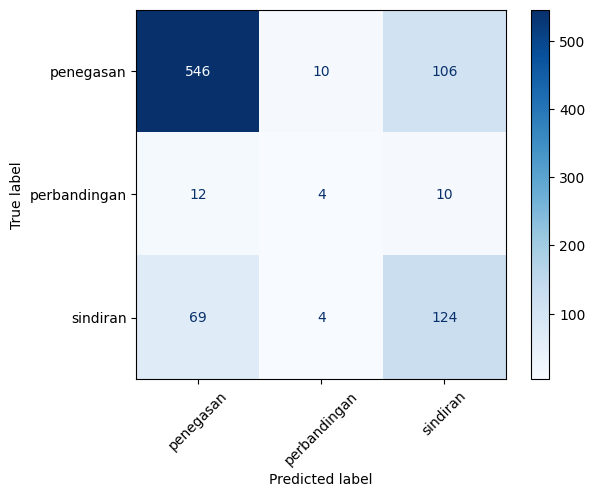

In [37]:
def bert_predict(trainer, texts):
    out = trainer.predict(to_dataset(texts))
    probs = softmax(out.predictions, axis=1)
    labels = np.array([id2label[i] for i in probs.argmax(1)])
    confidence = probs.max(1)
    return labels, confidence

predictors = {
    'Majority': majority.predict,
    'NB': nb_search.best_estimator_.predict,
    'SVM': svm_search.best_estimator_.predict,
    'IndoBERT': lambda t: bert_predict(bert_trainer, t)[0],
}

val_scores = {name: f1_score(y_val, predict(X_val), average='macro') for name, predict in predictors.items()}
print(pd.Series(val_scores).round(3).sort_values(ascending=False))

best_name = max(val_scores, key=val_scores.get)   # chosen on VALIDATION
y_pred_test = predictors[best_name](X_test)       # test used once

print(best_name)
print(classification_report(y_test, y_pred_test, digits=3, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test, xticks_rotation=45, cmap='Blues')
plt.show()

In [32]:
# uncertainty of the test score (bootstrap)
res = bootstrap(
    (np.array(y_test), np.array(y_pred_test)),
    lambda t, p: f1_score(t, p, average='macro'),
    paired=True,          # keep true label and prediction together
    vectorized=False,
    n_resamples=1000,
    method='percentile',  # simple and always defined
    random_state=42,
)
test_f1 = f1_score(y_test, y_pred_test, average='macro')
ci = res.confidence_interval
print(f'test macro F1 = {test_f1:.3f}, 95% CI {ci.low:.3f}-{ci.high:.3f}')

test macro F1 = 0.532, 95% CI 0.476-0.588


# Predict Data

In [33]:
output_df, start_date, end_date = prepare_time(
    predict_df[['Date', 'Media', 'Type', 'Mentions', 'Sentiment', 'Author']])
output_df['text_clean'] = output_df['Mentions'].fillna('').apply(clean)
mask = output_df['text_clean'].ne('')   # skip empty texts
print(f'predicting {mask.sum()} rows, skipping {(~mask).sum()} empty')

texts = output_df.loc[mask, 'text_clean']
if best_name == 'IndoBERT':
    output_df.loc[mask, 'predicted_majas'], output_df.loc[mask, 'confidence'] = bert_predict(bert_trainer, texts)
else:
    output_df.loc[mask, 'predicted_majas'] = predictors[best_name](texts)
output_df.head(20)

predicting 6190 rows, skipping 19 empty


Map:   0%|          | 0/6190 [00:00<?, ? examples/s]

,Date,Media,Type,Mentions,Sentiment,Author,text_clean,predicted_majas,confidence
6208,2026-10-16 00:00:00,Twitter,rt,"RT Pelantikan 2 Pejabat TNI, Prabowo Tunjuk Maruli Simanjuntak Jadi Wakil Panglima dan Tandyo Budi Revita sebagai KSAD #TNI #Prabowo #MaruliSimanjuntak #TandyoBudi #KSAD #Kabarterdepan https://t.co/kAIJbNasF1 https://t.co/7EL5sO67mu",Negative,@kabarterdepanmr,"rt pelantikan 2 pejabat tni, prabowo tunjuk maruli simanjuntak jadi wakil panglima dan tandyo budi revita sebagai ksad tni prabowo marulisimanjuntak tandyobudi ksad kabarterdepan",penegasan,0.779500
6207,2026-10-16 00:00:03,Youtube,mention,🇮🇩 INDONESIA MAJU #prabowo #viralvideo #youtubeshorts #viral #video #fyp #viralshorts #shorts,Positive,calonpemimpin,🇮🇩 indonesia maju prabowo viralvideo youtubeshorts viral video fyp viralshorts shorts,penegasan,0.735749
6206,2026-10-16 00:00:06,Youtube,mention,"&quot;KALAU PAK PRABOWO SAMPAI AKHIR 2026 TIDAK MELAKUKAN APA-APA ATAS KELUARGA SOLO, BELIAU KALAH&quot;. For Partnership, Please Contact:\nbisnis@forumkeadilan.com\nhttps://wa.me/628119899090\n\nDapatkan informasi terkini isu-isu hukum dan politik di Indonesia dengan Forum Keadilan. Download aplikasinya sekarang!\nPlaystore https://tinyurl.com/forumkeadilanplaystore\nAppStore https://tinyurl.com/forumkeadilanapps\nPortal https://forumkeadilan.com/\n\nApakah Anda peduli dengan isu-isu keadilan sosial dan ingin berkontribusi dalam menciptakan perubahan positif? Forum Keadilan adalah tempat yang tepat untuk Anda! Ikuti kami sekarang di:\nYouTube https://www.youtube.com/@forumkeadilanTV\nInstagram https://www.instagram.com/forumkeadilantv\nFB https://www.facebook.com/forumkeadilandotcom\nTiktok https://www.tiktok.com/@forumkeadilantv\n\n#menukwulandari #prabowosubianto #gibranrakabumingraka #jokowi #irianajokowi #keluargasolo #kertenegara #aliansirakyatmenggugat #arm #wakilpresiden #pencalonanwapres #politikindonesia #politiknasional #madilog #podcastmadilog #margisyarif #presidensial #pemerintahanprabowo #beritanasional #forumkeadilan",Positive,Forum Keadilan TV,"""kalau pak prabowo sampai akhir 2026 tidak melakukan apa-apa atas keluarga solo, beliau kalah"". for partnership, please contact: bisnis .com dapatkan informasi terkini isu-isu hukum dan politik di indonesia dengan forum keadilan. download aplikasinya sekarang! playstore appstore portal apakah anda peduli dengan isu-isu keadilan sosial dan ingin berkontribusi dalam menciptakan perubahan positif? forum keadilan adalah tempat yang tepat untuk anda! ikuti kami sekarang di: youtube instagram fb tiktok menukwulandari prabowosubianto gibranrakabumingraka jokowi irianajokowi keluargasolo kertenegara aliansirakyatmenggugat arm wakilpresiden pencalonanwapres politikindonesia politiknasional madilog podcastmadilog margisyarif presidensial pemerintahanprabowo beritanasional forumkeadilan",penegasan,0.721185
6205,2026-10-16 00:00:07,Youtube,mention,PRESIDEN PRABOWO INSTRUKSIKAN TRANSFORMASI MENYELURUH PLN. Saksikan update informasi terbaru di SurabayaTV channel digital 35 frekuensi 586.\n\nSurabayaTV\nTV Kota Pahlawan\n\n\nIKUTI KAMI DI SOSIAL MEDIA:\nFacebook: https://www.facebook.com/SurabayaTv/\nTiktok: https://www.tiktok.com/@surabayatv\nInstagram: https://www.instagram.com/surabayatv.official\nYoutube: https://www.youtube.com/channel/surabayatv\n\nKami sangat berterima kasih atas perhatian dan kontribusi penonton dalam membagikan dan menyukai channel kami...\n\nSalam SurabayaTV...\n\n#SURABAYATV #FRESH #UPDATE,Positive,NEWS SURABAYA TV,presiden prabowo instruksikan transformasi menyeluruh pln. saksikan update informasi terbaru di surabayatv channel digital 35 frekuensi 586. surabayatv tv kota pahlawan ikuti kami di sosial media: facebook: tiktok: instagram: youtube: kami sangat berterima beri atas perhatian dan kontribusi penonton dalam membagikan dan menyukai channel kami... salam surabayatv... surabayatv fresh update,penegasan,0.812215
6204,2026-10-16 00:00:09,News,mention,"Ke depan, BRI akan terus memperkua

In [34]:
print(output_df['predicted_majas'].value_counts(dropna=False, normalize=True))

if 'confidence' in output_df:
    # read the 10 least-confident predictions yourself: the fastest way
    # to catch a preprocessing mismatch between train and predict
    print(output_df['confidence'].describe())
    display(output_df.nsmallest(10, 'confidence')[['Mentions', 'predicted_majas', 'confidence']])

output_df.to_csv('predicted_results.csv', index=False, encoding='utf-8-sig')
files.download('predicted_results.csv')

predicted_majas
penegasan       0.626993
sindiran        0.351586
perbandingan    0.018360
NaN             0.003060
Name: proportion, dtype: float64
count    6190.000000
mean        0.690652
std         0.125417
min         0.337700
25%         0.587988
50%         0.740753
75%         0.802181
max         0.855894
Name: confidence, dtype: float64


Mentions  \
1157                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
# real-data check: label a sample by hand (count RTs once)
pool = output_df[mask].drop_duplicates(subset='text_clean')
sample = pool.sample(min(len(pool), 200), random_state=42)
sample[['Mentions', 'text_clean', 'predicted_majas']].assign(label_manual='').to_excel(
    'to_label_manually.xlsx', index=False)
files.download('to_label_manually.xlsx')
# open the file and fill the label_manual column, then upload it back to Colab

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:
# after manual labeling
checked = pd.read_excel('to_label_manually.xlsx')
print(classification_report(checked['label_manual'], checked['predicted_majas'], zero_division=0))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/_array_api.py:399: RuntimeWarning: invalid value encountered in cast
  return x.astype(dtype, copy=copy, casting=casting)


ValueError: Input y_true contains NaN.